# Update:

The kernel has been updated for the new teset and train datasets.

# Introduction:

Being anonymous over the internet can sometimes make people say nasty things that they normally would not in real life. Let's filter out the hate from our platforms one comment at a time.

## Objective:

To create an EDA/feature-engineering starter notebook for toxic comment classification.

## Data Overview:

The dataset here is from wiki corpus dataset which was rated by human raters for toxicity. The corpus contains 63M comments from discussions relating to user pages and articles dating from 2004-2015.

Different platforms/sites can have different standards for their toxic screening process. Hence the comments are tagged in the following five categories

* toxic
* severe_toxic
* obscene
* threat
* insult
* identity_hate

The tagging was done via **crowdsourcing** which means that the dataset was rated by different people and the tagging might not be 100% accurate too. The same concern is being discussed [here](https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/discussion/46131).

The [source paper](https://arxiv.org/pdf/1610.08914.pdf) also contains more interesting details about the dataset creation.

### Note:
A [New test dataset](https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/discussion/46177) is being created by the organizers as the test set labels are present [here](https://figshare.com/articles/Wikipedia_Talk_Labels_Toxicity/4563973).

The kernel has been updated for the new data.

In [1]:
import os
for f in os.listdir('./input'):
    print(f'{os.path.getsize(os.path.join("./input", f)) / 1024**2:.1f} MB\t{f}')

6.0 MB	sample_submission.csv
57.6 MB	test.csv
4.7 MB	test_labels.csv
65.6 MB	train.csv


In [2]:
import pandas as pd
import numpy as np

import gc
import time
import warnings

from imageio.v2 import imread
from scipy import sparse
import scipy.stats as ss

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from PIL import Image
import matplotlib_venn as venn

import string
import re
import nltk
from nltk.corpus import stopwords
import spacy
from nltk import pos_tag
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from nltk.tokenize import TweetTokenizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, HashingVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_is_fitted
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split

start_time = time.time()
color = sns.color_palette()
sns.set_style('dark')
eng_stopwords = set(stopwords.words('english'))
warnings.filterwarnings('ignore')

lem = WordNetLemmatizer()
tokenizer = TweetTokenizer()

%matplotlib inline

In [3]:
train = pd.read_csv('./input/train.csv')
test = pd.read_csv('./input/test.csv')

In [4]:
train.tail(10)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
159561,ffd2e85b07b3c7e4,"""\nNo he did not, read it again (I would have ...",0,0,0,0,0,0
159562,ffd72e9766c09c97,"""\n Auto guides and the motoring press are not...",0,0,0,0,0,0
159563,ffe029a7c79dc7fe,"""\nplease identify what part of BLP applies be...",0,0,0,0,0,0
159564,ffe897e7f7182c90,Catalan independentism is the social movement ...,0,0,0,0,0,0
159565,ffe8b9316245be30,The numbers in parentheses are the additional ...,0,0,0,0,0,0
159566,ffe987279560d7ff,""":::::And for the second time of asking, when ...",0,0,0,0,0,0
159567,ffea4adeee384e90,You should be ashamed of yourself \n\nThat is ...,0,0,0,0,0,0
159568,ffee36eab5c267c9,"Spitzer \n\nUmm, theres no actual article for ...",0,0,0,0,0,0
159569,fff125370e4aaaf3,And it looks like it was actually you who put ...,0,0,0,0,0,0
159570,fff46fc426af1f9a,"""\nAnd ... I really don't think you understand...",0,0,0,0,0,0


In [5]:
nrow_train = train.shape[0]
nrow_test = test.shape[0]
sum = nrow_train + nrow_test
print('     : train : test')
print('rows :',nrow_train,':', nrow_test)
print('perc :',round(nrow_train*100/sum), ':', round(nrow_test*100/sum))

     : train : test
rows : 159571 : 153164
perc : 51 : 49


There is a 30:70 train:test split and the test set might change in the future too.

Let's take a look at the class imbalance in the train set.

### Class Imbalance:

In [6]:
x = train.iloc[:, 2:].sum()

rowsums = train.iloc[:, 2:].sum(axis=1)
train['clean'] = (rowsums==0)

train['clean'].sum()
print('Total comments = ', len(train))
print('Total clean comments = ', train['clean'].sum())
print('Total tags =', x.sum())

Total comments =  159571
Total clean comments =  143346
Total tags = 35098


In [7]:
print('Check for missing values in Train dataset')
null_check = train.isnull().sum()
print(null_check)
print('Check for missing values in Test dataset')
null_check = test.isnull().sum()
print(null_check)
print('filling NA with \"unknown\"')
train['comment_text'].fillna('unknown', inplace=True)
test['comment_text'].fillna('unknown', inplace=True)

Check for missing values in Train dataset
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
clean            0
dtype: int64
Check for missing values in Test dataset
id              0
comment_text    0
dtype: int64
filling NA with "unknown"


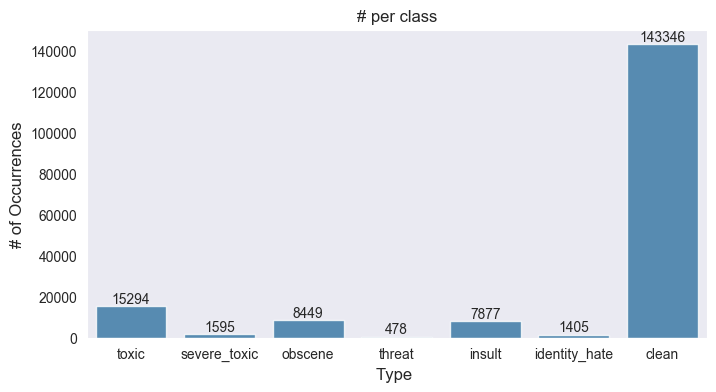

In [9]:
x = train.iloc[:, 2:].sum()

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=x.index, y=x.values, alpha=0.8)
plt.title('# per class')
plt.ylabel('# of Occurrences', fontsize=12)
plt.xlabel('Type ', fontsize=12)

rects = ax.patches
labels = x.values
for rect, label in zip(rects, labels):
    height = rect.get_height()
    ax.text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha='center', va='bottom')

plt.show()

* The toxicity is not evenly spread out across classes. Hence we might face class imbalance problems
* There are ~95k comments in the training dataset and there are ~21k tags and ~86k clean comments!?
  * This is only possible when multiple tags are associated with each comment (eg) a comment can be classified as both toxic and obscene.

### Multi-tagging:

Let's check how many comments have multiple tags.

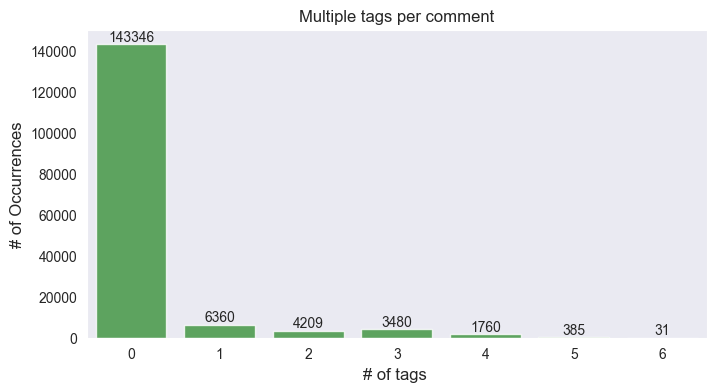

In [10]:
x = rowsums.value_counts()

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=x.index, y=x.values, alpha=0.8, color=color[2])
plt.title('Multiple tags per comment')
plt.ylabel('# of Occurrences', fontsize=12)
plt.xlabel('# of tags ', fontsize=12)

rects = ax.patches
labels = x.values
for rect, label in zip(rects, labels):
    height = rect.get_height()
    ax.text(rect.get_x() + rect.get_width() / 2, height + 5, label, ha='center', va='bottom')

plt.show()

Only ~10% of the total comments have some sort of toxicity in them. There are certain comments(20) that are marked as all of the above!

### Which tags go together?

Now let's have a look at how often the tags occur together. A good indicator of that would be a correlation plot.

<Axes: >

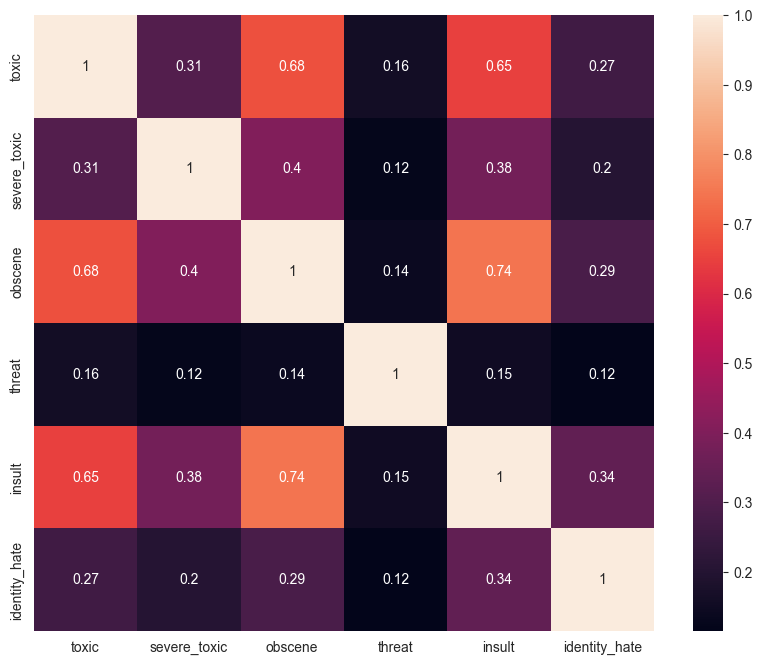

In [11]:
temp_df = train.iloc[:, 2:-1]

corr = temp_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr,
            xticklabels=corr.columns.values,
            yticklabels=corr.columns.values, annot=True)

The above plot indicates a pattern of co-occurance but Pandas's default Corr function which uses Pearson correlation does not apply here, since the variables involved are Categorical (binary) variables.

So, to find a pattern between two categorical variables we can use other tools like

* Confusion matrix/Crosstab
* Cramer's V Statistic
  * Cramer's V stat is an extension of the chi-square test where the extent/strength of association is also measured

In [12]:
def highlight_min(data, color='yellow'):
    '''
    highlight the maximum in a Series or DataFrame
    '''
    attr = 'background-color: {}'.format(color)
    if data.ndim == 1:
        is_min = data == data.min()
        return [attr if v else '' for v in is_min]
    else:
        is_max = data == data.min().min()
        return pd.DataFrame(np.where(is_min, attr, ''),
                            index=data.index, columns=data.columns)

In [13]:
main_col = 'toxic'
corr_mats = []
for other_col in temp_df.columns[1:]:
    confusion_matrix = pd.crosstab(temp_df[main_col], temp_df[other_col])
    corr_mats.append(confusion_matrix)
out = pd.concat(corr_mats, axis=1, keys=temp_df.columns[1:])

out = out.style.apply(highlight_min, axis=0)
out

The above table represents the Crosstab/confusion matrix of Toxic comments with the other classes.

Some interesting observations:

* A Severe toxic comment is always toxic
* Other classes seem to be a subset of toxic barring a few exceptions

In [14]:
def cramers_corrected_stat(confusion_matrix):
    '''
    calculate Cramers V statistic for categorical-categorical association.
    uses correction from Bergsma and Wicher,
    Journal of the Korean Statistical Society 42 (2013): 323-328
    '''
    chi2 = ss.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2/n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1) * (r-1)) / (n-1))
    rcorr = r - ((r-1)**2) / (n-1)
    kcorr = k - ((k-1)**2) / (n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

In [15]:
import pandas as pd
col1 = 'toxic'
col2 = 'severe_toxic'
confusion_matrix = pd.crosstab(temp_df[col1], temp_df[col2])
print('Confusion matrix between toxic and severe toxic:')
print(confusion_matrix)
new_corr = cramers_corrected_stat(confusion_matrix)
print("The correlation between Toxic and Severe toxic using Cramer's stat=", new_corr)

Confusion matrix between toxic and severe toxic:
severe_toxic       0     1
toxic                     
0             144277     0
1              13699  1595
The correlation between Toxic and Severe toxic using Cramer's stat= 0.30850290540548614


### Example Comments:

In [16]:
print('toxic:')
print(train[train.severe_toxic==1].iloc[3, 1])

toxic:
Hi 

Im a fucking bitch.

50.180.208.181


In [17]:
print('severe_toxic:')
print(train[train.severe_toxic==1].iloc[4, 1])

severe_toxic:
What a motherfucking piece of crap those fuckheads for blocking us!


In [18]:
print('Threat:')
print(train[train.threat==1].iloc[1, 1])

Threat:
I think that your a Fagget get a oife and burn in Hell I hate you 'm sorry we cant have any more sex i'm running out of conndoms


In [19]:
print('Obscene:')
print(train[train.obscene==1].iloc[1, 1])

Obscene:
You are gay or antisemmitian? 

Archangel WHite Tiger

Meow! Greetingshhh!

Uh, there are two ways, why you do erased my comment about WW2, that holocaust was brutally slaying of Jews and not gays/Gypsys/Slavs/anyone...

1 - If you are anti-semitian, than shave your head bald and go to the skinhead meetings!

2 - If you doubt words of the Bible, that homosexuality is a deadly sin, make a pentagram tatoo on your forehead go to the satanistic masses with your gay pals!

3 - First and last warning, you fucking gay - I won't appreciate if any more nazi shwain would write in my page! I don't wish to talk to you anymore!

Beware of the Dark Side!


In [20]:
print('identity_hate:')
print(train[train.identity_hate==1].iloc[4, 1])

identity_hate:
u r a tw@ fuck off u gay boy.U r smelly.Fuck ur mum poopie


That was a whole lot of toxicity. Some weird observations:

* Some of the comments are extremely and mere copy paste of the same thing
* Comments can still contain IP addresses(eg:62.158.73.165), usernames(eg:ARKJEDI10) and some mystery numbers(i assume is article-IDs)

Point 2 can cause huge overfitting.

## Wordclouds - Frequent words:

Now, let's take a look at words that are associated with these classes.

Chart Desc: The visuals here are word clouds (ie) more frequent words appear bigger. A cool way to create word clouds with funky pics is given [here](https://www.kaggle.com/arthurtok/spooky-nlp-and-topic-modelling-tutorial). It involves the following steps.

```
* Search for an imge and its base 64 encoding
* Paste encoding in a cell and convert it using codecs package to image
* Create word cloud with the new image as a mask
```

A simpler way would be to create a new kaggle dataset and import images from there.

In [24]:
!dir .\input\imageforkernel
stopword = set(STOPWORDS)

 Volume in drive C has no label.
 Volume Serial Number is 2602-0473

 Directory of c:\Users\USER\Desktop\AI_study\kaggle_transcription\Natural language processing - classification, regression\3rd level. Toxic Comment Classification Challenge\input\imageforkernel

2026-10-17  오후 03:22    <DIR>          .
2026-10-17  오후 03:22    <DIR>          ..
2026-10-17  오후 03:22            16,867 anger.png
2026-10-17  오후 03:22            14,885 biohazard-symbol.png
2026-10-17  오후 03:22             9,149 bomb.png
2026-10-17  오후 03:22            10,939 gas-mask.png
2026-10-17  오후 03:22             8,698 megaphone.png
2026-10-17  오후 03:22            18,070 safe-zone.png
2026-10-17  오후 03:22             9,224 swords.png
2026-10-17  오후 03:22            16,306 toxic-sign.png
               8 File(s)        104,138 bytes
               2 Dir(s)  175,261,782,016 bytes free


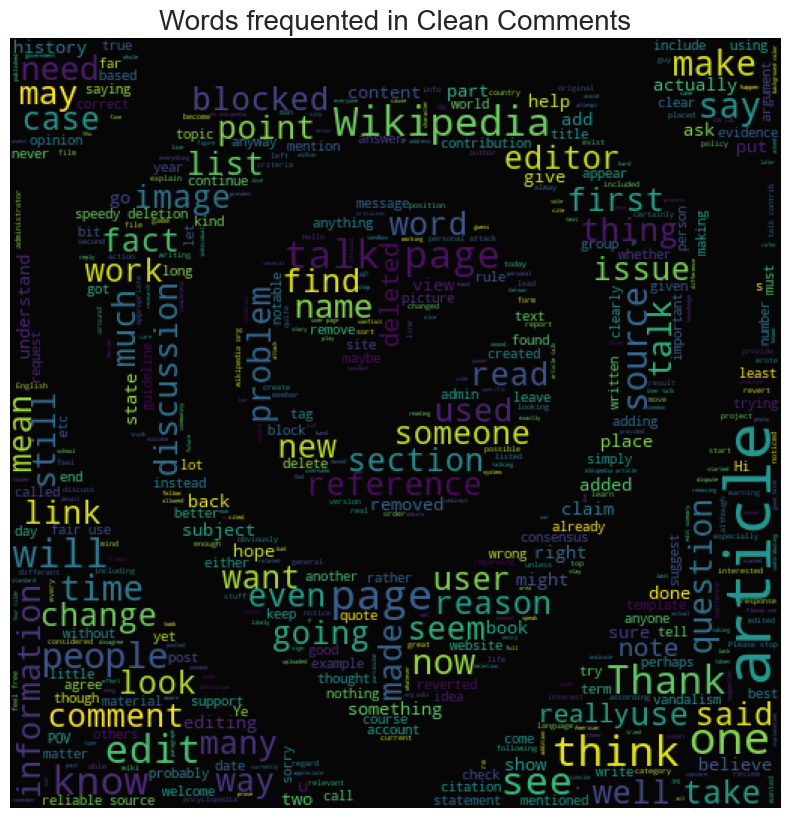

In [25]:
clean_mask = np.array(Image.open('./input/imageforkernel/safe-zone.png'))
clean_mask = clean_mask[:, :, 1]

subset = train[train.clean==True]
text = subset.comment_text.values
wc = WordCloud(background_color='black', max_words=2000, mask=clean_mask, stopwords=stopword)
wc.generate(' '.join(text))
plt.figure(figsize=(20, 10))
plt.axis('off')
plt.title('Words frequented in Clean Comments', fontsize=20)
plt.imshow(wc.recolor(colormap='viridis', random_state=17), alpha=0.98)
plt.show()

In [ ]:
toxic_mask = np.array(Image.open('./input/imageforkernel/toxic-sign.png'))
toxic_mask = toxic_mask[:, :, 1]

subset = train[train.toxic==1]
text = subset.comment_text.values
wc = WordCloud(background_color='black', max_words=4000, mask=toxic_mask, stopwords=stopword)
wc.generate(' '.join(text))
plt.figure(figsize=(20, 20))
plt.subplot(221)
plt.axis('off')
plt.title('Words frequented in Toxic Comments', fontsize=20)
plt.imshow(wc.color(colormap='gist_earth', random_state=244), alpha=0.98)

plt.subplot(222)
severe_toxic_mask = np.array(Image.open('./input/imageforkernel/bomb.png'))
severe_toxic_mask = severe_toxic_mask[:, :, 1]
subset = train[train.severe_toxic==1]
text = subset.comment_text.values
wc = WordCloud(background_color='black', max_words=2000, mask=severe_toxic_mask, stopwords=stopword)
wc.generate(' '.join(text))
plt.axis('off')
plt.title('Words frequented in Severe Toxic Comments', fontsize=20)
plt.imshow(wc.recolor(colormap='Reds', random_state=244), alpha=0.98)

plt.subplot(223)
threat_mask = np.array(Image.open('./input/imageforkernel/anger.png'))
threat_mask = threat_mask[:, :, 1]
subset = train[train.threat==1]
text = subset.comment_text.values
wc = WordCloud(background_color='black', max_words=2000, mask=threat_mask, stopwords=stopword)
wc.generate(' '.join(text))
plt.axis('off')
plt.title('Words frequented in Threatening Comments', fontsize=20)
plt.imshow(wc.recolor(colormap='summer', random_state=2534), alpha=0.98)

plt.subplot(224)
insult_mask = np.array(Image.open('./input/imageforkernel/swords.png'))
insult_mask = insult_mask[:, :, 1]
